# Day 18/100 — ProductPhoto QA | FULL MASTER v1

Inputs: `/kaggle/input/datasets/loliwibu/finegrain-products`, `/kaggle/input/datasets/loliwibu/kadid10k`, `/kaggle/input/datasets/loliwibu/spaq-data`.

**Research contract:** KADID has 10,125 synthetically distorted images from 81 reference photos and a subjective 1–5 quality score (higher = better). SPAQ has smartphone-photo subjective MOS and quality attributes, not merchant pass/fail. Finegrain product segmentation images are useful as an application smoke test, **not** a quality-label dataset. Do not merge unlike labels or claim a verified product pass/fail accuracy. Split KADID by source reference image; test remains held out. SPAQ split ZIP (.z01–.zip) is not assumed extracted. No fabricated results.

In [1]:
%pip -q install "scikit-learn>=1.3,<2" "openpyxl>=3,<4" "opencv-python-headless>=4.8,<5" "joblib>=1.3,<2"

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os,json,re,zipfile,sys,hashlib,shutil
import cv2,joblib,numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from IPython.display import display
ROOTS={'kadid':Path('/kaggle/input/datasets/loliwibu/kadid10k'),'spaq':Path('/kaggle/input/datasets/loliwibu/spaq-data'),'finegrain':Path('/kaggle/input/datasets/loliwibu/finegrain-products')}
OUT=Path('/kaggle/working/productphoto_master_v1')
for sub in ['models','reports','assets/plots','exports','notebooks']:(OUT/sub).mkdir(parents=True,exist_ok=True)
SEED=42; MAX_IMAGES=10125; MAX_PRODUCT_DEMOS=20
FEATURES=['laplacian_var','tenengrad','brightness_mean','brightness_std','dark_fraction','bright_fraction','contrast_p95_p5','colorfulness','entropy','width','height']
def save(name,obj): (OUT/'reports'/name).write_text(json.dumps(obj,indent=2,default=str,ensure_ascii=False),encoding='utf-8')
print({k:v.exists() for k,v in ROOTS.items()});assert ROOTS['kadid'].exists(), 'Attach KADID input first'

{'kadid': True, 'spaq': True, 'finegrain': True}


## 1 — Three-source inventory, schema & split ZIP audit
Inspect without decompressing a 35GB multipart SPAQ archive; if no images are directly accessible, report that and do not claim SPAQ validation.

In [3]:
inventory=[]
for key,root in ROOTS.items():
    if not root.exists():continue
    fs=[p for p in root.rglob('*') if p.is_file()]
    print(key,'files=',len(fs),'GB=',round(sum(p.stat().st_size for p in fs)/2**30,3))
    for p in sorted(fs,key=lambda x:x.stat().st_size,reverse=True)[:70]:
        inventory.append({'dataset':key,'relative_path':str(p.relative_to(root)),'size_MB':round(p.stat().st_size/2**20,2)})
inv=pd.DataFrame(inventory);display(inv.head(80));inv.to_csv(OUT/'reports/source_inventory.csv',index=False)
sroot=ROOTS['spaq'];spaq_files=[p for p in sroot.rglob('*') if p.is_file()] if sroot.exists() else []
spaq_split=[p for p in spaq_files if re.search(r'\.z\d{2}$',p.name.lower())]
spaq_images=[p for p in spaq_files if p.suffix.lower() in ('.jpg','.jpeg','.png','.webp')]
spaq_labels=[p for p in spaq_files if p.suffix.lower() in ('.csv','.xlsx','.xls')]
spaq_audit={'split_parts':len(spaq_split),'direct_images':len(spaq_images),'annotation_files':[str(p.relative_to(sroot)) for p in spaq_labels], 'evaluated':False,'reason':'Different MOS label/domain; this version audits SPAQ separately. Multipart ZIP may require external extraction.'}
save('spaq_audit.json',spaq_audit)
print('SPAQ:',spaq_audit)

kadid files= 10345 GB= 2.86
spaq files= 10 GB= 30.002
finegrain files= 9 GB= 0.11


,dataset,relative_path,size_MB
0,kadid,kadid10k/kadid10k/kadid10k/images/I27_14_05.png,0.54
1,kadid,kadid10k/kadid10k/kadid10k/images/I32_14_05.png,0.53
2,kadid,kadid10k/kadid10k/kadid10k/images/I72_14_05.png,0.53
3,kadid,kadid10k/kadid10k/kadid10k/images/I37_14_05.png,0.53
4,kadid,kadid10k/kadid10k/kadid10k/images/I33_14_05.png,0.53
...,...,...,...
75,spaq,SPAQ/SPAQ.z06,5120.00
76,spaq,SPAQ/Annotations-20250710T143903Z-1-001/Annota...,1.19
77,spaq,SPAQ/Annotations-20250710T143903Z-1-001/Annota...,0.55
78,spaq,SPAQ/Annotations-20250710T143903Z-1-001/Annota...,0.43


SPAQ: {'split_parts': 6, 'direct_images': 0, 'annotation_files': ['SPAQ/Annotations-20250710T143903Z-1-001/Annotations/EXIF_tags.xlsx', 'SPAQ/Annotations-20250710T143903Z-1-001/Annotations/MOS and Image attribute scores.xlsx', 'SPAQ/Annotations-20250710T143903Z-1-001/Annotations/Scene category labels.xlsx'], 'evaluated': False, 'reason': 'Different MOS label/domain; this version audits SPAQ separately. Multipart ZIP may require external extraction.'}


## 2 — KADID metadata and source-reference groups
Stop rather than silently training wrong labels or random splitting distorted variants of one reference.

In [4]:
kroot=ROOTS['kadid']; csvs=sorted(kroot.rglob('*.csv'),key=lambda p:('dmos' not in p.name.lower(),len(p.parts)))
for p in csvs[:8]:
    d=pd.read_csv(p,nrows=3);print(p.name,list(d.columns));display(d.head(2))
found=None
for path in csvs:
    try:
        frame=pd.read_csv(path)
        cols={str(x).strip().lower():x for x in frame.columns}
        imagecol=next((cols[x] for x in ['dist_img','distorted_image','image','filename','img'] if x in cols),None)
        refcol=next((cols[x] for x in ['ref_img','reference_image','reference','ref'] if x in cols),None)
        scorecol=next((cols[x] for x in ['dmos','mos','score','quality_score'] if x in cols),None)
        if imagecol and scorecol and len(frame)>2000:found=(frame,imagecol,refcol,scorecol,path);break
    except Exception as e:print('Skipped',path.name,str(e)[:100])
assert found,'No recognized KADID score CSV; please share printed metadata columns.'
df,imgcol,refcol,scorecol,metapath=found
df['score']=pd.to_numeric(df[scorecol],errors='coerce');df=df.dropna(subset=['score',imgcol]).copy()
assert (df.score.between(1,5)).mean()>.95,'KADID labels outside expected 1–5; do not continue.'
if refcol is not None:df['group']=df[refcol].astype(str).str.lower()
else:
    df['group']=df[imgcol].astype(str).str.extract(r'(?i)(i\d{2,3})[_-]')[0].str.lower()
    assert df.group.notna().all(),'Reference IDs cannot be parsed safely; need an explicit ref_img column.'
assert df.group.nunique()>30,'Group inference looks wrong.'
print('rows',len(df),'references',df.group.nunique(),'score distribution');display(df.score.describe())

dmos.csv ['dist_img', 'ref_img', 'dmos', 'var']


,dist_img,ref_img,dmos,var
0,I01_01_01.png,I01.png,4.57,0.496
1,I01_01_02.png,I01.png,4.33,0.869


rows 10125 references 81 score distribution


count    10125.000000
mean         3.032633
std          1.082680
min          1.000000
25%          2.130000
50%          3.000000
75%          4.070000
max          4.930000
Name: score, dtype: float64

## 3 — Resolve files and extract real OpenCV features
If the mirror contains only ZIPs, decompress KADID or upload the image folder first. Full 10,125 images is feasible on Kaggle CPU.

In [5]:
EXT={'.jpg','.jpeg','.png','.bmp','.webp'}
images=[p for p in kroot.rglob('*') if p.is_file() and p.suffix.lower() in EXT]
lookup={}
for p in images:lookup.setdefault(p.name.lower(),p)
df['path']=df[imgcol].astype(str).map(lambda x:str(lookup.get(Path(x).name.lower(),'')))
missing=int((df.path=='').sum());print('images',len(images),'matches',len(df)-missing,'missing',missing)
assert len(images)>0,'KADID images not extracted; ZIP-only inputs are not supported for CV features.'
assert missing/len(df)<.05,'Image mapping incomplete; inspect metadata filenames vs folder names.'
df=df[df.path!=''].copy()
def compute_features(im):
    if im is None:raise ValueError('Unreadable image')
    h,w=im.shape[:2]
    if max(h,w)>640:
        ratio=640/max(h,w);im=cv2.resize(im,(int(w*ratio),int(h*ratio)),interpolation=cv2.INTER_AREA)
    gray=cv2.cvtColor(im,cv2.COLOR_BGR2GRAY)
    gx=cv2.Sobel(gray,cv2.CV_32F,1,0);gy=cv2.Sobel(gray,cv2.CV_32F,0,1)
    b,g,r=cv2.split(im.astype(np.float32));rg=np.abs(r-g);yb=np.abs((r+g)/2-b)
    hist=np.bincount(gray.ravel(),minlength=256).astype(float);hist/=hist.sum()
    p5,p95=np.percentile(gray,[5,95])
    return [float(cv2.Laplacian(gray,cv2.CV_64F).var()),float(np.mean(gx*gx+gy*gy)),float(gray.mean()),float(gray.std()),float((gray<45).mean()),float((gray>215).mean()),float(p95-p5),float(np.sqrt(rg.std()**2+yb.std()**2)+0.3*np.sqrt(rg.mean()**2+yb.mean()**2)),float(-(hist[hist>0]*np.log2(hist[hist>0])).sum()),float(w),float(h)]
rows=[];failed=[]
for i,r in enumerate(df.head(MAX_IMAGES).itertuples(index=False)):
    try:
        im=cv2.imread(r.path)
        vals=compute_features(im)
        rows.append(dict(filename=Path(r.path).name,score=float(r.score),group=str(r.group),**dict(zip(FEATURES,vals))))
    except Exception as e:failed.append({'filename':str(r.path),'error':str(e)})
    if (i+1)%2000==0:print('processed',i+1)
ft=pd.DataFrame(rows);print('features',ft.shape,'failures',len(failed));assert len(ft)>=2000,'Insufficient extracted images.'
save('kadid_image_failures.json',failed);ft.to_csv(OUT/'reports/kadid_image_features.csv',index=False);display(ft.head(3))

images 10338 matches 10125 missing 0
processed 2000
processed 4000
processed 6000
processed 8000
processed 10000
features (10125, 14) failures 0


,filename,score,group,laplacian_var,tenengrad,brightness_mean,brightness_std,dark_fraction,bright_fraction,contrast_p95_p5,colorfulness,entropy,width,height
0,I01_01_01.png,4.57,i01.png,590.687300,8720.918945,108.703196,52.492067,0.145228,0.001643,161.0,48.524651,7.565864,512.0,384.0
1,I01_01_02.png,4.33,i01.png,276.212742,6893.642090,108.697255,52.011274,0.141652,0.000916,160.0,48.460159,7.544807,512.0,384.0
2,I01_01_03.png,2.67,i01.png,47.272816,4020.686279,108.370794,51.393025,0.141449,0.000539,158.0,48.492577,7.521988,512.0,384.0


## 4 — Leakage-safe train/validation/test + baseline champion selection
**GroupShuffleSplit by original KADID reference photo.** Select champion by validation MAE; test once. Metrics are quality-score regression, *not product pass/fail accuracy*.

In [6]:
s1=GroupShuffleSplit(n_splits=1,test_size=.15,random_state=SEED)
devix,testix=next(s1.split(ft,groups=ft.group));dev,test=ft.iloc[devix],ft.iloc[testix]
s2=GroupShuffleSplit(n_splits=1,test_size=.17647059,random_state=SEED+1)
trix,vix=next(s2.split(dev,groups=dev.group));train,val=dev.iloc[trix],dev.iloc[vix]
for a,b in [(train,val),(train,test),(val,test)]:assert set(a.group).isdisjoint(b.group)
splits={n:{'n':len(d),'groups':int(d.group.nunique()),'score_mean':float(d.score.mean())} for n,d in [('train',train),('val',val),('test',test)]};save('split_audit.json',splits);print(splits)
models={'dummy':DummyRegressor(strategy='median'),
 'ridge':Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('reg',Ridge(alpha=10.))]),
 'histgb':Pipeline([('impute',SimpleImputer(strategy='median')),('reg',HistGradientBoostingRegressor(max_iter=180,learning_rate=.05,max_leaf_nodes=20,random_state=SEED))])}
results=[]
for name,m in models.items():
    m.fit(train[FEATURES],train.score);pr=np.clip(m.predict(val[FEATURES]),1,5)
    results.append({'model':name,'val_MAE':float(mean_absolute_error(val.score,pr)),'val_RMSE':float(np.sqrt(mean_squared_error(val.score,pr)))})
ranking=pd.DataFrame(results).sort_values(['val_MAE','model']);display(ranking);ranking.to_csv(OUT/'reports/model_selection.csv',index=False)
champion_name=str(ranking.iloc[0].model);champion=models[champion_name];print('Chosen by validation only:',champion_name)

{'train': {'n': 6875, 'groups': 55, 'score_mean': 3.0325047272727272}, 'val': {'n': 1625, 'groups': 13, 'score_mean': 3.064504615384615}, 'test': {'n': 1625, 'groups': 13, 'score_mean': 3.0013046153846155}}


,model,val_MAE,val_RMSE
2,histgb,0.819218,1.038764
1,ridge,0.900278,1.049545
0,dummy,0.934277,1.071203


Chosen by validation only: histgb


## 5 — Frozen held-out test, plots and human-readable diagnostics
A model that predicts KADID well might still fail on real marketplace product photography.

{
  "champion": "histgb",
  "test_rows": 1625,
  "reference_groups": 13,
  "MAE": 0.7682952859270697,
  "RMSE": 0.9669035725157733,
  "R2": 0.1925177073295007,
  "protocol": "heldout reference groups (KADID synthetic-distortion IQA)"
}


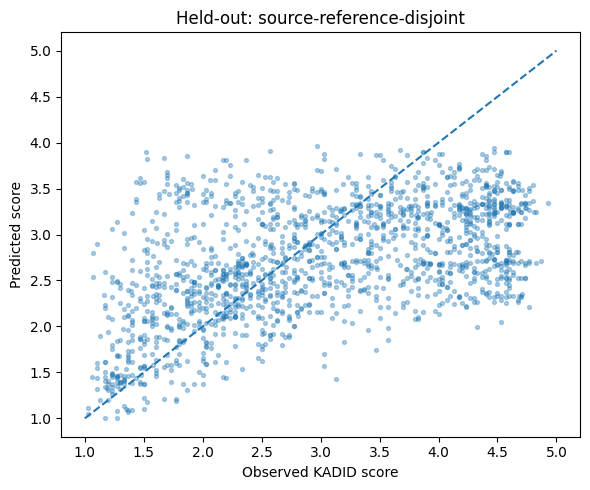

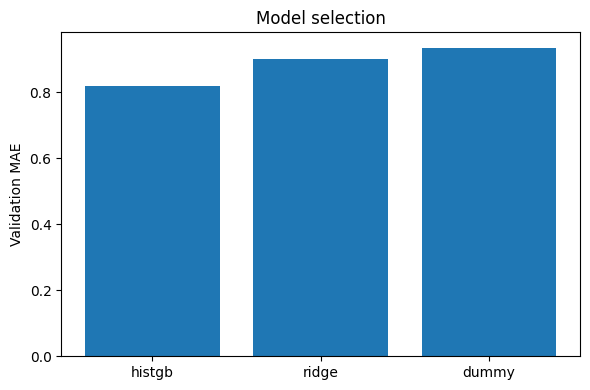

In [7]:
pred=np.clip(champion.predict(test[FEATURES]),1,5)
metrics={'champion':champion_name,'test_rows':len(test),'reference_groups':test.group.nunique(),
 'MAE':float(mean_absolute_error(test.score,pred)),'RMSE':float(np.sqrt(mean_squared_error(test.score,pred))),'R2':float(r2_score(test.score,pred)),
 'protocol':'heldout reference groups (KADID synthetic-distortion IQA)'}
print(json.dumps(metrics,indent=2));save('kadid_heldout_metrics.json',metrics)
outpred=test[['filename','group','score']].copy();outpred['predicted']=pred;outpred['absolute_error']=abs(outpred.score-outpred.predicted)
outpred.to_csv(OUT/'exports/kadid_heldout_predictions.csv',index=False)
fig,ax=plt.subplots(figsize=(6,5));ax.scatter(test.score,pred,s=8,alpha=.35);ax.plot([1,5],[1,5],'--');ax.set(xlabel='Observed KADID score',ylabel='Predicted score',title='Held-out: source-reference-disjoint')
fig.tight_layout();fig.savefig(OUT/'assets/plots/heldout_quality_scatter.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(6,4));ax.bar(ranking.model,ranking.val_MAE);ax.set(ylabel='Validation MAE',title='Model selection');fig.tight_layout();fig.savefig(OUT/'assets/plots/validation_comparison.png',dpi=160);plt.show()

## 6 — Prototype blur/brightness checker (no pass/fail truth)
These **illustrative** thresholds produce PASS_PROVISIONAL or REVIEW and reasons. They have not been calibrated against seller acceptance decisions. Do not present their flagged rate as classification accuracy.

Policy flags — NOT accuracy: {'PASS_PROVISIONAL': 1372, 'REVIEW': 253}


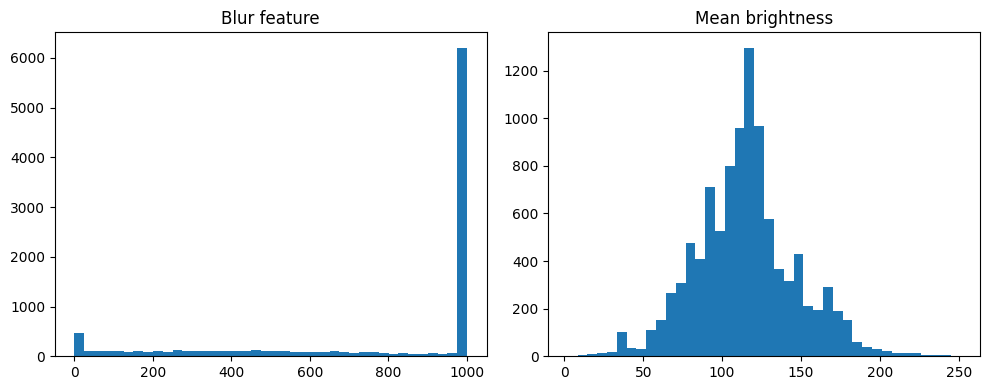

In [8]:
POLICY={'laplacian_min':75.,'brightness_min':65.,'brightness_max':205.,'dark_fraction_max':.48,'bright_fraction_max':.48}
def policy_fn(row):
    reasons=[]
    if row['laplacian_var']<POLICY['laplacian_min']:reasons.append('possible_blur')
    if row['brightness_mean']<POLICY['brightness_min'] or row['dark_fraction']>POLICY['dark_fraction_max']:reasons.append('possibly_too_dark')
    if row['brightness_mean']>POLICY['brightness_max'] or row['bright_fraction']>POLICY['bright_fraction_max']:reasons.append('possibly_too_bright')
    return ('REVIEW' if reasons else 'PASS_PROVISIONAL','|'.join(reasons))
test_flags=test.apply(lambda row:policy_fn(row),axis=1)
print('Policy flags — NOT accuracy:',pd.Series([x[0] for x in test_flags]).value_counts().to_dict())
save('policy.json',{'thresholds':POLICY,'status':'Uncalibrated demonstration only; NOT valid seller acceptance ground truth'})
fig,axs=plt.subplots(1,2,figsize=(10,4));axs[0].hist(ft.laplacian_var.clip(upper=1000),bins=40);axs[0].set_title('Blur feature');axs[1].hist(ft.brightness_mean,bins=40);axs[1].set_title('Mean brightness');fig.tight_layout();fig.savefig(OUT/'assets/plots/image_feature_distribution.png',dpi=160);plt.show()

## 7 — Product-domain smoke test + SPAQ audit
Product images are for interface testing. SPAQ MOS has a different protocol; this version does not fabricate cross-dataset MOS results.

In [9]:
froot=ROOTS['finegrain'];fimgs=[p for p in froot.rglob('*') if p.is_file() and p.suffix.lower() in ('.jpg','.jpeg','.png','.webp')] if froot.exists() else []
demos=[]
for p in fimgs[:MAX_PRODUCT_DEMOS]:
    im=cv2.imread(str(p));
    if im is None:continue
    feats=dict(zip(FEATURES,compute_features(im)));status,reasons=policy_fn(feats)
    demos.append({'file':p.name,'status':status,'reasons':reasons,'quality_truth':'UNAVAILABLE',**feats})
if demos:display(pd.DataFrame(demos).head());pd.DataFrame(demos).to_csv(OUT/'exports/product_smoke_predictions.csv',index=False)
for path in spaq_labels[:6]:
    try:
        dat=pd.read_csv(path,nrows=3) if path.suffix.lower()=='.csv' else pd.read_excel(path,nrows=3)
        print('SPAQ metadata candidate:',path.name,list(dat.columns));display(dat.head(2))
    except Exception as e:print('Metadata preview error:',str(e)[:250])
save('finegrain_audit.json',{'image_files':len(fimgs),'demo_rows':len(demos),'truth':'not quality annotated'})
print('SPAQ available direct images',len(spaq_images),'split pieces',len(spaq_split),'MOS evaluation: NOT PERFORMED')

SPAQ metadata candidate: EXIF_tags.xlsx ['Image name', 'Focal length', 'F-number', 'Exposure time', 'ISO', 'Brightness', 'Flash', 'Time', 'Unnamed: 8']


,Image name,Focal length,F-number,Exposure time,ISO,Brightness,Flash,Time,Unnamed: 8
0,00001.jpg,4.20,1.7,0.10,200,-1.21,0,-0.965926,-0.258819
1,00002.jpg,4.04,2.0,0.05,400,3.00,0,-1.000000,0.000000


SPAQ metadata candidate: MOS and Image attribute scores.xlsx ['Image name', 'MOS', 'Brightness', 'Colorfulness', 'Contrast', 'Noisiness', 'Sharpness']


,Image name,MOS,Brightness,Colorfulness,Contrast,Noisiness,Sharpness
0,00001.jpg,48.86,47.43,55.57,55.71,37.86,42.57
1,00002.jpg,62.50,55.38,67.13,53.13,57.50,47.50


SPAQ metadata candidate: Scene category labels.xlsx ['Image name', 'Animal', 'Cityscape', 'Human', 'Indoor scene', 'Landscape', 'Night scene', 'Plant', 'Still-life', 'Others']


,Image name,Animal,Cityscape,Human,Indoor scene,Landscape,Night scene,Plant,Still-life,Others
0,00001.jpg,0,0.333333,0,0,0,0.333333,0,0.333333,0
1,00002.jpg,0,0.500000,0,0,0,0.500000,0,0.000000,0


SPAQ available direct images 0 split pieces 6 MOS evaluation: NOT PERFORMED


## 8 — Export inference-ready model + exact feature/policy contract + release ZIP
All outputs retained with source distinctions. No raw third-party images, no fake scores, no binary approval claims.

In [10]:
joblib.dump(champion,OUT/'models/kadid_quality_proxy.joblib')
contract={'model_file':'kadid_quality_proxy.joblib','feature_names':FEATURES,'opencv_version':cv2.__version__,'policy':POLICY,
 'quality_score_source':'KADID synthetic distortions, 1–5 higher is better','pass_fail':'uncalibrated policy only','model_selection':'lowest validation MAE'}
(OUT/'models/model_config.json').write_text(json.dumps(contract,indent=2),encoding='utf-8')
reloaded=joblib.load(OUT/'models/kadid_quality_proxy.joblib');delta=float(np.max(abs(reloaded.predict(test[FEATURES].head(40))-champion.predict(test[FEATURES].head(40)))))
assert delta<1e-9;save('inference_parity.json',{'max_abs_delta':delta,'passed':True})
summary={'project':'ProductPhoto QA','day':18,'heldout':metrics,'selection':ranking.to_dict('records'),'split':splits,'finegrain_smoke_count':len(demos),'spaq':spaq_audit,
 'limitations':['No verified product-photo pass/fail labels','KADID not product-domain representative','SPAQ audit only, no MOS evaluation','Blur metric is content dependent']}
save('final_summary.json',summary)
release=Path('/kaggle/working/ProductPhotoQA_Day18_FULL_MASTER_v1_RELEASE.zip')
with zipfile.ZipFile(release,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in OUT.rglob('*'):
        if p.is_file() and p.name!='kadid_image_features.csv':z.write(p,str(p.relative_to(OUT)))
with zipfile.ZipFile(release) as z:
    assert z.testzip() is None
    assert 'reports/final_summary.json' in z.namelist() and 'models/kadid_quality_proxy.joblib' in z.namelist()
print('RELEASE:',release,'MB:',round(release.stat().st_size/2**20,2))
print('Save Version → Save & Run All; audit JSON and charts before claims.')

RELEASE: /kaggle/working/ProductPhotoQA_Day18_FULL_MASTER_v1_RELEASE.zip MB: 0.37
Save Version → Save & Run All; audit JSON and charts before claims.
